# PBL JS11 - Klasifikasi SVM

**Nama:** Agus
**NIM:** 244107020049

[Sumber modul](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js11-klasifikasi-2)

Notebook ini menerapkan langkah-langkah jobsheet JS11 pada **dataset PBL: Malicious URL Detection**
(`Malicious URL Detection.csv` di root repositori). Dataset berisi 783.705 URL dengan kolom `url` dan `type`, terbagi ke 7 kelas:
`benign`, `legitimate`, `defacement`, `phishing`, `malware`, `spam`, dan `Exploit`.
URL sudah dinormalisasi oleh sumbernya (huruf kecil, tanpa `http(s)://` dan `www.`).
Fungsi muat data dan ekstraksi fitur leksikal ada di modul bersama [`pbl_url.py`](../pbl_url.py), sehingga semua notebook PBL memakai definisi fitur yang sama.

**Pemetaan langkah jobsheet → dataset PBL:**


| Jobsheet JS11 | Penerapan pada URL |
| --- | --- |
| Praktikum 1-3 - SVM linier, non-linier (RBF), pengaruh C | SVM pada 28 fitur leksikal, pengaruh kernel dan C |
| Praktikum 4 - GridSearchCV, classification report, confusion matrix | Tuning C/gamma RBF |
| Tugas 1 - enam kombinasi split 70:30 / 80:20 × kernel linear/poly/RBF | Tabel akurasi enam kombinasi |
| Tugas 2 / Praktikum 5 - fitur buatan + SVM | SVM linier (LinearSVC) pada TF-IDF n-gram karakter seluruh data |

In [1]:
import sys, time
from pathlib import Path
sys.path.insert(0, str(Path('..').resolve()))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pbl_url
np.random.seed(42)
print('Kernel:', sys.executable)

Kernel: /Users/jergal/College/machine-learning-smt-5/.venv/bin/python


In [2]:
df = pbl_url.load_urls()
print(df.shape)
df.head()

(783705, 2)


,url,type
0,mp3raid.com/music/krizz_kaliko.html,benign
1,bopsecrets.org/rexroth/cr/1.htm,benign
2,buzzfil.net/m/show-art/ils-etaient-loin-de-s-i...,benign
3,espn.go.com/nba/player/_/id/3457/brandon-rush,benign
4,yourbittorrent.com/?q=anthony-hamilton-soulife,benign


In [3]:
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC, LinearSVC
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
X = pbl_url.lexical_features(df['url']); y = df['type'].to_numpy()
# SVC berkernel memiliki kompleksitas latih ~O(n^2), sehingga dipakai subset stratified 30.000 URL
sub, _ = train_test_split(np.arange(len(df)), train_size=30000, stratify=y, random_state=42)
Xs, ys = np.log1p(X.iloc[sub].clip(lower=0)).to_numpy(), y[sub]

## Tugas 1 - Enam kombinasi split dan kernel

In [4]:
rows = []
for test_size, split_name in [(0.3, '70:30'), (0.2, '80:20')]:
    Xtr, Xte, ytr, yte = train_test_split(Xs, ys, test_size=test_size, stratify=ys, random_state=42)
    for kernel in ['linear', 'poly', 'rbf']:
        model = make_pipeline(StandardScaler(), SVC(kernel=kernel, C=1.0, gamma='scale', degree=3, cache_size=1000))
        t0 = time.perf_counter(); model.fit(Xtr, ytr); dur = time.perf_counter() - t0
        p_tr, p_te = model.predict(Xtr), model.predict(Xte)
        rows.append({'split': split_name, 'kernel': kernel, 'train_acc': accuracy_score(ytr, p_tr), 'test_acc': accuracy_score(yte, p_te),
                     'test_macro_F1': f1_score(yte, p_te, average='macro'), 'n_support_vectors': model[-1].n_support_.sum(), 'fit_s': dur})
six = pd.DataFrame(rows); six.round(4)

,split,kernel,train_acc,test_acc,test_macro_F1,n_support_vectors,fit_s
0,70:30,linear,0.6751,0.6714,0.4526,14330,8.6732
1,70:30,poly,0.7611,0.7373,0.5640,12439,4.5003
2,70:30,rbf,0.7832,0.7606,0.4345,11761,3.8196
3,80:20,linear,0.6704,0.6632,0.4742,16385,10.6239
4,80:20,poly,0.7605,0.7397,0.5664,13972,5.6513
5,80:20,rbf,0.7821,0.7628,0.4354,13356,4.6804


## Praktikum 3 - Pengaruh parameter C (kernel RBF, split 80:20)

,train_acc,test_acc,test_macro_F1,n_SV
C,,,,
0.01,0.6652,0.6562,0.3213,17958
0.10,0.7455,0.7338,0.4162,15207
1.00,0.7821,0.7628,0.4354,13356
10.00,0.8162,0.7782,0.5934,12246
100.00,0.8440,0.7818,0.6081,11406


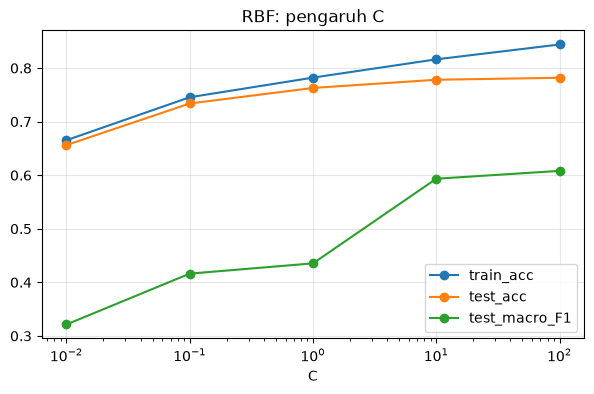

In [5]:
Xtr, Xte, ytr, yte = train_test_split(Xs, ys, test_size=0.2, stratify=ys, random_state=42)
rows = []
for C in [0.01, 0.1, 1, 10, 100]:
    m = make_pipeline(StandardScaler(), SVC(kernel='rbf', C=C, gamma='scale', cache_size=1000)).fit(Xtr, ytr)
    rows.append({'C': C, 'train_acc': accuracy_score(ytr, m.predict(Xtr)), 'test_acc': accuracy_score(yte, m.predict(Xte)),
                 'test_macro_F1': f1_score(yte, m.predict(Xte), average='macro'), 'n_SV': m[-1].n_support_.sum()})
c_tbl = pd.DataFrame(rows).set_index('C'); display(c_tbl.round(4))
c_tbl[['train_acc', 'test_acc', 'test_macro_F1']].plot(logx=True, marker='o', figsize=(7, 4), title='RBF: pengaruh C'); plt.grid(alpha=.3); plt.show()

## Praktikum 4 - GridSearchCV C dan gamma

Parameter terbaik: {'svc__C': 10, 'svc__gamma': 0.1} | CV macro-F1: 0.5106


              precision    recall  f1-score   support

     Exploit     1.0000    0.5000    0.6667         2
      benign     0.7908    0.8833    0.8345      3265
  defacement     0.8735    0.7764    0.8221       729
  legitimate     0.0000    0.0000    0.0000        44
     malware     0.8909    0.8122    0.8497       181
    phishing     0.7349    0.6416    0.6851      1758
        spam     0.5000    0.0476    0.0870        21

    accuracy                         0.7878      6000
   macro avg     0.6843    0.5230    0.5636      6000
weighted avg     0.7807    0.7878    0.7809      6000



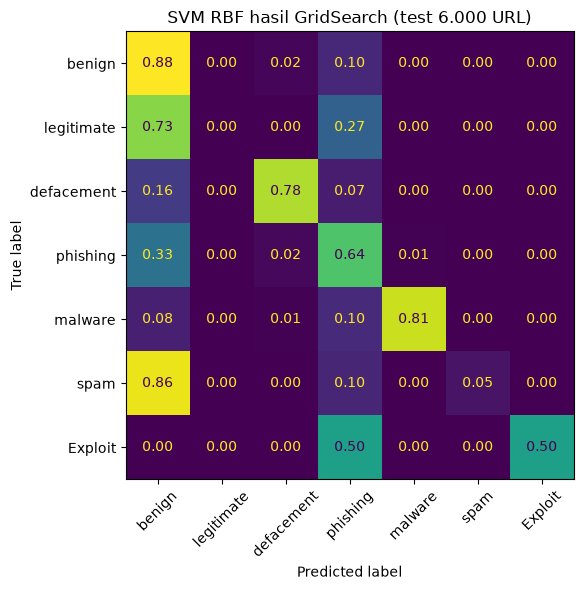

In [6]:
grid = GridSearchCV(make_pipeline(StandardScaler(), SVC(kernel='rbf', cache_size=1000)),
                    {'svc__C': [1, 10, 100], 'svc__gamma': ['scale', 0.01, 0.1]},
                    cv=StratifiedKFold(3, shuffle=True, random_state=0), scoring='f1_macro', n_jobs=-1).fit(Xtr, ytr)
print('Parameter terbaik:', grid.best_params_, '| CV macro-F1:', round(grid.best_score_, 4))
p_best = grid.predict(Xte)
print(classification_report(yte, p_best, digits=4, zero_division=0))
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(yte, p_best, labels=pbl_url.CLASSES, normalize='true', values_format='.2f', ax=ax, colorbar=False, xticks_rotation=45)
plt.title('SVM RBF hasil GridSearch (test 6.000 URL)'); plt.tight_layout(); plt.show()

## Tugas 2 - SVM linier pada fitur teks seluruh data

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import hstack, csr_matrix
idx_tr, idx_te = train_test_split(np.arange(len(df)), test_size=0.2, stratify=y, random_state=42)
t0 = time.perf_counter()
vec = TfidfVectorizer(analyzer='char', ngram_range=(3, 5), min_df=3, max_features=500000, sublinear_tf=True, dtype=np.float32)
Tt, Tv = vec.fit_transform(df['url'].iloc[idx_tr]), vec.transform(df['url'].iloc[idx_te])
lsvc = LinearSVC(C=0.5).fit(Tt, y[idx_tr]); p_l = lsvc.predict(Tv)
print(f'LinearSVC TF-IDF char: {time.perf_counter() - t0:.0f} s, acc={accuracy_score(y[idx_te], p_l):.4f}, macro-F1={f1_score(y[idx_te], p_l, average="macro"):.4f}')

sc = StandardScaler().fit(np.log1p(X.iloc[idx_tr].clip(lower=0)))
L_tr = csr_matrix(sc.transform(np.log1p(X.iloc[idx_tr].clip(lower=0))).astype(np.float32))
L_te = csr_matrix(sc.transform(np.log1p(X.iloc[idx_te].clip(lower=0))).astype(np.float32))
lsvc2 = LinearSVC(C=0.5).fit(hstack([Tt, L_tr]).tocsr(), y[idx_tr]); p_c = lsvc2.predict(hstack([Tv, L_te]).tocsr())
print(f'LinearSVC TF-IDF char + 28 fitur leksikal: acc={accuracy_score(y[idx_te], p_c):.4f}, macro-F1={f1_score(y[idx_te], p_c, average="macro"):.4f}')
print(classification_report(y[idx_te], p_c, digits=4, zero_division=0))

LinearSVC TF-IDF char: 126 s, acc=0.9375, macro-F1=0.8263


LinearSVC TF-IDF char + 28 fitur leksikal: acc=0.9384, macro-F1=0.8321


              precision    recall  f1-score   support

     Exploit     1.0000    0.8163    0.8989        49
      benign     0.9405    0.9588    0.9496     85286
  defacement     0.9916    0.9930    0.9923     19053
  legitimate     0.7749    0.1807    0.2931      1162
     malware     0.9873    0.9195    0.9522      4718
    phishing     0.9081    0.9018    0.9049     45923
        spam     0.9900    0.7200    0.8337       550

    accuracy                         0.9384    156741
   macro avg     0.9418    0.7843    0.8321    156741
weighted avg     0.9376    0.9384    0.9365    156741



## Analisis

**Tugas 1 - enam kombinasi (SVC, C=1, 30 ribu URL):**

| Split | Kernel | Train acc | Test acc | Test macro-F1 | Support vector |
| --- | --- | --- | --- | --- | --- |
| 70:30 | linear | 0,675 | 0,671 | 0,453 | 14.330 |
| 70:30 | poly | 0,761 | 0,737 | **0,564** | 12.439 |
| 70:30 | RBF | 0,783 | **0,761** | 0,435 | 11.761 |
| 80:20 | linear | 0,670 | 0,663 | 0,474 | 16.385 |
| 80:20 | poly | 0,761 | 0,740 | **0,566** | 13.972 |
| 80:20 | RBF | 0,782 | **0,763** | 0,435 | 13.356 |

* Perbedaan split 70:30 dan 80:20 kecil (≤ 1 poin), sedangkan pilihan kernel jauh lebih berpengaruh. Kernel linier paling buruk karena kelas URL tidak terpisah linier dalam ruang 28 fitur leksikal.
* RBF memiliki **akurasi tertinggi tetapi macro-F1 terendah** di antara kernel non-linier. Dengan C=1, margin lebar membuat kelas minoritas (spam, legitimate, Exploit) terserap ke kelas besar. Akurasi menyembunyikan hal ini (Sokolova & Lapalme, 2009).
* Banyaknya support vector (> 40% data latih) menunjukkan kelas-kelasnya sangat tumpang tindih. Waktu latih SVC berkernel tumbuh sekitar kuadrat terhadap jumlah data, sehingga SVC tidak praktis untuk 627 ribu URL.

**Pengaruh C (RBF).** Menaikkan C dari 0,01 ke 100 menaikkan macro-F1 dari 0,321 ke 0,608 dan mengurangi support vector (17.958 → 11.406). Celah train-test juga melebar (0,844 vs 0,782 pada C=100). C besar memperkecil toleransi terhadap kesalahan sehingga kelas kecil mulai dipisahkan, tetapi model menjadi lebih *overfit* (Cortes & Vapnik, 1995).

**GridSearchCV** memilih C=10, γ=0,1 (CV macro-F1 0,511). Pada data test: accuracy 0,788 dan macro-F1 0,564. Recall `legitimate` 0 dan `spam` 0,05, sehingga SVM pada fitur leksikal tidak dapat mengenali kedua kelas ini. Hsu dkk. (2003) menganjurkan *grid search* C-γ dengan CV seperti ini. Namun dengan 3-fold pada 24 ribu data, kelas Exploit hanya memiliki sekitar 2 sampel per fold, sehingga skor CV untuk kelas langka tidak stabil.

**Tugas 2 - SVM linier pada teks URL, seluruh data:**

| Model | Accuracy | Macro-F1 |
| --- | --- | --- |
| SVC RBF hasil GridSearch, 28 fitur leksikal (24 ribu latih) | 0,788 | 0,564 |
| LinearSVC, TF-IDF n-gram karakter 3-5 (627 ribu latih) | 0,938 | 0,826 |
| **LinearSVC, TF-IDF n-gram karakter + 28 fitur leksikal** | **0,938** | **0,832** |

LinearSVC (LIBLINEAR, Fan dkk., 2008) dapat dilatih pada **seluruh** 627 ribu URL dengan 500 ribu fitur dalam ~2 menit, dan macro-F1 naik 26 poin. Ini sejalan dengan Joachims (1998): fitur teks berdimensi sangat tinggi dan *sparse* umumnya terpisah secara linier, sehingga kernel non-linier tidak diperlukan. Ma dkk. (2009) juga mendapati model linier pada *bag-of-features* URL mencapai akurasi 95-99%. Menambahkan 28 fitur leksikal memberi tambahan kecil (+0,6 poin macro-F1). Per kelas, defacement (F1 0,992), malware (0,952), benign (0,950), dan phishing (0,905) sangat baik. Exploit mencapai recall 0,82 dengan precision 1,00. **Legitimate tetap menjadi kelas tersulit** (recall 0,18), karena URL-nya berupa domain saja yang tidak dapat dibedakan secara leksikal dari domain benign.

## Rujukan

1. Cortes, C., & Vapnik, V. (1995). Support-vector networks. *Machine Learning*, 20(3), 273-297. https://doi.org/10.1007/BF00994018
2. Hsu, C.-W., Chang, C.-C., & Lin, C.-J. (2003). *A Practical Guide to Support Vector Classification* (Technical Report). National Taiwan University.
3. Fan, R.-E., Chang, K.-W., Hsieh, C.-J., Wang, X.-R., & Lin, C.-J. (2008). LIBLINEAR: A library for large linear classification. *Journal of Machine Learning Research*, 9, 1871-1874.
4. Joachims, T. (1998). Text categorization with support vector machines: Learning with many relevant features. *European Conference on Machine Learning (ECML)*, LNCS 1398, 137-142. https://doi.org/10.1007/BFb0026683
5. Ma, J., Saul, L. K., Savage, S., & Voelker, G. M. (2009). Beyond blacklists: Learning to detect malicious web sites from suspicious URLs. *Proceedings of the 15th ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*, 1245-1254. https://doi.org/10.1145/1557019.1557153
6. Mamun, M. S. I., Rathore, M. A., Lashkari, A. H., Stakhanova, N., & Ghorbani, A. A. (2016). Detecting malicious URLs using lexical analysis. *Network and System Security (NSS 2016)*, LNCS 9955, 467-482. https://doi.org/10.1007/978-3-319-46298-1_30
7. He, H., & Garcia, E. A. (2009). Learning from imbalanced data. *IEEE Transactions on Knowledge and Data Engineering*, 21(9), 1263-1284. https://doi.org/10.1109/TKDE.2008.239